# Modellkonsistenz

In [16]:
import sys
import os
import dotenv

# Get the current directory
current_dir = os.getcwd()

# Go up one level to the parent directory
parent_dir = os.path.dirname(current_dir)

# Add the parent directory to the Python path
sys.path.append(parent_dir)

In [17]:
from portfolio_ai import PortfolioAIAssistant

In [18]:
assistant = PortfolioAIAssistant(
    provider="ollama",
    model="qwen3:14b",
    finance_provider="yfinance",
    ensemble=False,
)

In [ ]:
use_azure_openai_instead = False

if use_azure_openai_instead:

    assistant = PortfolioAIAssistant(
        provider="openai",
        model="gpt-4o",
        finance_provider="yfinance",
        ensemble=False,
        openai_api_key=os.getenv("AZURE_API_KEY"),
    )


    # Override normal OpenAI LangChain class with Azures
    from langchain_openai import AzureChatOpenAI

    assistant.chat = AzureChatOpenAI(
        model="gpt-4o",
        api_key=os.getenv("AZURE_API_KEY"),
        azure_endpoint=os.getenv("AZURE_URL_ENDPOINT"),
        azure_deployment="gpt-4o",
        api_version="2024-06-01",
        temperature=2, # and with 0.2
    )

In [20]:

pf = assistant.new_portfolio("Sample Portfolio", "Long-term growth / balanced risk")
pf.add_asset("MBGAF", name="Mercedes-Benz Group")
#pf.add_trade("MBG.DE", quantity=10, price=50.10, date_str="2023-05-01")
#pf.add_trade("MBG.DE", quantity=56, price=52.00, date_str="2023-06-01")

pf.add_asset("GOOG", name="Alphabet")
#pf.add_trade("GOOG", quantity=25, price=134.50, date_str="2023-02-15")

pf.add_asset("ASML", name="ASML Holding N.V.")

pf.add_asset("DKILY", name="Daikin Industries")
#pf.add_asset("EUNL", name="iShares Core MSCI World UCITS ETF USD (Acc)")

In [21]:
from datetime import datetime

result_saves_dict = {}

In [ ]:
for i in range(10):

    print("Running iteration", i)

    current_timestamp = datetime.now().isoformat(timespec='seconds')

    try:
        result = assistant.evaluate_portfolio(pf)
    except:
        pass

    result_saves_dict[current_timestamp] = result

Running iteration 0
Evaluating MBGAF ...
Getting quantitative data for MBGAF took 0.44s
Getting LLM asset analysis for Mercedes-Benz Group took 130.71s
Running iteration 1
Evaluating MBGAF ...
Getting quantitative data for MBGAF took 0.84s


In [ ]:
# just temporary
result_saves_dict_backup = result_saves_dict

In [ ]:


print(result_saves_dict)

{'2025-10-05T19:26:06': {'portfolio_name': 'Sample Portfolio', 'investor_goals': 'Long-term growth / balanced risk', 'assets': {'MBGAF': {'name': 'Mercedes-Benz Group', 'trades': [], 'evaluation_results': {'urgency': 70, 'buy': 40, 'sell': 10, 'hold': 50, 'potential_upside': 65, 'potential_downside': 35, 'explanation_evaluation': "Mercedes-Benz Group is focusing on electrification and innovation, positioning itself well in the evolving automotive industry. The company shows resilience in financial performance despite supply chain challenges. While current valuation metrics like the low PE ratio indicate potential upside, risks from regulatory challenges and competition need to be considered. Overall, holding is recommended, with a potential buy for those optimistic about the company's strategic initiatives and market expansion.", 'prompts': {'llm_brief_prompt': 'Give a concise business overview, recent events, and key risks/opportunities for Mercedes-Benz Group.', 'assessment_messages'

In [ ]:
def print_dict_tree(d, indent=0, hide_values=False, max_depth=None, current_depth=0, only_show_the_following_keys=None):
    if max_depth is not None and current_depth >= max_depth:
        return  # Stop recursion if the maximum depth is reached

    if only_show_the_following_keys is None:
        only_show_the_following_keys = []  # Initialize to an empty list if None

    for key, value in d.items():
        print(' ' * indent + str(key))  # Print the key with indentation

        # Check if the current key is in the list of keys to show
        if isinstance(value, dict):  # If the value is a dictionary, recurse
            print_dict_tree(value, indent + 4, hide_values, max_depth, current_depth + 1, only_show_the_following_keys)
        elif not hide_values or key in only_show_the_following_keys:  # Print the value if hide_values is False or key is in the list
            print(' ' * (indent + 4) + str(value))  # Print the value with indentation

In [ ]:
print_dict_tree(result_saves_dict, only_show_the_following_keys=["urgency", "buy", "sell", "hold", "potential_upside", "potential_downside"], hide_values=True)

# Additional options:
# Only certain keys

2025-10-05T19:26:06
    portfolio_name
    investor_goals
    assets
        MBGAF
            name
            trades
            evaluation_results
                urgency
                    70
                buy
                    40
                sell
                    10
                hold
                    50
                potential_upside
                    65
                potential_downside
                    35
                explanation_evaluation
                prompts
                    llm_brief_prompt
                    assessment_messages
                last_evaluated_at
        GOOG
            name
            trades
            evaluation_results
                urgency
                    60
                buy
                    50
                sell
                    10
                hold
                    40
                potential_upside
                    70
                potential_downside
                    30
            

In [ ]:
print(result["assets"]["MBGAF"]["evaluation_results"])

{'urgency': 70, 'buy': 40, 'sell': 10, 'hold': 50, 'potential_upside': 65, 'potential_downside': 35, 'explanation_evaluation': "Mercedes-Benz Group is focusing on electrification and innovation, positioning itself well in the evolving automotive industry. The company shows resilience in financial performance despite supply chain challenges. While current valuation metrics like the low PE ratio indicate potential upside, risks from regulatory challenges and competition need to be considered. Overall, holding is recommended, with a potential buy for those optimistic about the company's strategic initiatives and market expansion.", 'prompts': {'llm_brief_prompt': 'Give a concise business overview, recent events, and key risks/opportunities for Mercedes-Benz Group.', 'assessment_messages': [{'role': 'system', 'content': 'You are a disciplined equity analyst. Return strictly the requested JSON schema. Numbers are integers [0..100].'}, {'role': 'human', 'content': 'You may receive any subset

In [ ]:
from collections import defaultdict, Counter
from typing import Dict, Any, List, Union, Optional, Tuple, Set
import math

Number = Union[int, float]

# ------------------------- helpers (unchanged) -------------------------

def _safe_number(x: Any) -> Optional[float]:
    """Return float(x) if x is a finite number, otherwise None."""
    if isinstance(x, (int, float)) and math.isfinite(x):
        return float(x)
    return None

def _mean(values: List[float]) -> float:
    """Arithmetic mean; assumes values is non-empty."""
    return sum(values) / len(values)

def _mean_abs_dev(values: List[float], mean_value: float) -> float:
    """Mean absolute deviation from the mean (in the same units as values)."""
    return sum(abs(v - mean_value) for v in values) / len(values)

def _mean_rel_dev(values: List[float], mean_value: float) -> Optional[float]:
    """
    Mean absolute relative deviation: mean(|v - mean|) / |mean|.
    Returns None if mean is (near) zero and no sensible relative baseline exists.
    """
    denom = abs(mean_value)
    if denom < 1e-12:
        # If all values are ~0, relative deviation is undefined -> None
        if all(abs(v) < 1e-12 for v in values):
            return None
        # Else fall back to mean absolute value as a softer baseline
        denom = sum(abs(v) for v in values) / len(values)
        if denom < 1e-12:
            return None
    return _mean_abs_dev(values, mean_value) / denom

def _max_abs_dev(values: List[float], mean_value: float) -> float:
    """Maximum absolute deviation from the mean."""
    return max(abs(v - mean_value) for v in values)

def _identical_count(values: List[float], rounding_decimals: int = 4) -> int:
    """
    Count of the most frequent (i.e., largest group of) identical values.
    Uses rounding to make equality robust to tiny float noise.
    """
    rounded = [round(v, rounding_decimals) for v in values]
    freq = Counter(rounded)
    return max(freq.values()) if freq else 0

# ------------------------- asset utilities -------------------------

def _extract_asset_display_and_aliases(asset_key: Optional[str], asset: Dict[str, Any]) -> Tuple[str, Set[str]]:
    """
    Determine a human-friendly display name for the asset and a set of aliases
    that can be used for filtering (e.g., ticker, symbol, provided key, etc.).
    """
    # Common fields we might find in various data structures
    candidates = [
        asset.get("name"),
        asset.get("display_name"),
        asset.get("longName"),
        asset.get("shortName"),
        asset.get("symbol"),
        asset.get("ticker"),
        asset.get("id"),
        asset.get("isin"),
        asset_key,
    ]
    # Choose first non-empty string as display name
    display = next((str(c) for c in candidates if isinstance(c, str) and c.strip()), "Unknown Asset")
    # Build alias set for filtering (case-insensitive)
    aliases = {str(c).strip().lower() for c in candidates if isinstance(c, str) and c.strip()}
    return display, aliases

# ------------------------- main function (UPDATED) -------------------------

def aggregate_evaluation_stats(
    result_saves_dict: Dict[str, Any],
    specific_assets: Optional[List[str]] = None,
) -> Dict[str, Dict[str, Dict[str, Any]]]:
    """
    Aggregate evaluation statistics PER ASSET across all timestamps.

    Changes vs your previous version:
      1) The returned dictionary is now keyed first by the **asset name**, then by metric:
           {
             "Asset A": { "urgency": {...}, "buy": {...}, ... },
             "Asset B": { ... }
           }
      2) 'specific_assets' is now a LIST. When provided, only assets whose name/ticker/etc
         matches any element (case-insensitive) are included.

    The metrics computed for each asset/metric are:
      - mean                         (in %)
      - avg_abs_dev_pp              (mean absolute deviation in percentage points)
      - avg_rel_dev_pct             (mean absolute relative deviation, in % of mean)
      - identical_values_count      (max frequency of identical values; rounded to 4dp)
      - max_abs_dev_pp              (max absolute deviation from mean, in percentage points)
      - count, unique_values
      - orig_values_list            (all raw values collected)

    Expected structure in `result_saves_dict`:
      result_saves_dict[timestamp]["assets"] may be either:
        • a dict: { "<asset_key>": { "evaluation_results": {...}, ... }, ... }
        • a list: [ { "name": "...", "evaluation_results": {...}, ... }, ... ]
    """
    METRICS = [
        "urgency",
        "buy",
        "sell",
        "hold",
        "potential_upside",
        "potential_downside",
    ]

    # Normalize asset filter to a lowercase set of search terms
    filter_set: Optional[Set[str]] = None
    if specific_assets:
        filter_set = {str(x).strip().lower() for x in specific_assets if isinstance(x, str) and x.strip()}

    # collected[asset_display][metric] -> list of values across timestamps
    collected: Dict[str, Dict[str, List[float]]] = defaultdict(lambda: defaultdict(list))

    # -------- traverse all timestamps and assets --------
    for _ts, payload in (result_saves_dict or {}).items():
        assets = (payload or {}).get("assets", {})

        # Case 1: dict of assets
        if isinstance(assets, dict):
            iterable = list(assets.items())
        # Case 2: list of assets
        elif isinstance(assets, list):
            iterable = [(None, a) for a in assets]  # asset_key unknown
        else:
            continue

        for asset_key, asset in iterable:
            if not isinstance(asset, dict):
                continue

            #display_name, aliases = _extract_asset_display_and_aliases(asset_key, asset)
            display_name = asset_key

            # Apply filter if provided
            if filter_set is not None and aliases.isdisjoint(filter_set):
                continue

            eval_res = asset.get("evaluation_results", {})
            if not isinstance(eval_res, dict):
                continue

            for m in METRICS:
                val = _safe_number(eval_res.get(m))
                if val is not None:
                    collected[display_name][m].append(val)

    # -------- compute stats per asset & metric --------
    def _empty_stats():
        return {
            "count": 0,
            "mean": None,
            "avg_abs_dev_pp": None,
            "avg_rel_dev_pct": None,
            "identical_values_count": 0,
            "max_abs_dev_pp": None,
            "unique_values": 0,
            "orig_values_list": [],
        }

    result: Dict[str, Dict[str, Dict[str, Any]]] = {}

    for asset_name, metric_dict in collected.items():
        asset_stats: Dict[str, Dict[str, Any]] = {}

        for m in METRICS:
            values = metric_dict.get(m, [])
            if not values:
                asset_stats[m] = _empty_stats()
                continue

            mu = _mean(values)
            mad = _mean_abs_dev(values, mu)
            mrd = _mean_rel_dev(values, mu)  # fraction
            max_dev = _max_abs_dev(values, mu)
            ident_ct = _identical_count(values, rounding_decimals=4)

            asset_stats[m] = {
                "count": len(values),
                "mean": mu,
                "avg_abs_dev_pp": mad,
                "avg_rel_dev_pct": (mrd * 100.0) if mrd is not None else None,
                "identical_values_count": ident_ct,
                "max_abs_dev_pp": max_dev,
                "unique_values": len(set(round(v, 4) for v in values)),
                "orig_values_list": list(values),
            }

        # Ensure all metrics exist even if missing
        for m in METRICS:
            asset_stats.setdefault(m, _empty_stats())

        result[asset_name] = asset_stats

    return result

# ------------------------- example usage -------------------------
# stats_by_asset = aggregate_evaluation_stats(result_saves_dict, specific_assets=["Mercedes-Benz Group", "MBG.DE"])
# print(stats_by_asset["Mercedes-Benz Group"]["buy"])


In [ ]:
stats_summary = aggregate_evaluation_stats(result_saves_dict)
print(stats_summary)

{'MBGAF': {'urgency': {'count': 4, 'mean': 70.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 4, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [70.0, 70.0, 70.0, 70.0]}, 'buy': {'count': 4, 'mean': 40.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 4, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [40.0, 40.0, 40.0, 40.0]}, 'sell': {'count': 4, 'mean': 10.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 4, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [10.0, 10.0, 10.0, 10.0]}, 'hold': {'count': 4, 'mean': 50.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 4, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list': [50.0, 50.0, 50.0, 50.0]}, 'potential_upside': {'count': 4, 'mean': 65.0, 'avg_abs_dev_pp': 0.0, 'avg_rel_dev_pct': 0.0, 'identical_values_count': 4, 'max_abs_dev_pp': 0.0, 'unique_values': 1, 'orig_values_list

/tmp/ipykernel_32203/4291259859.py:158: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", max(n_assets, 3))


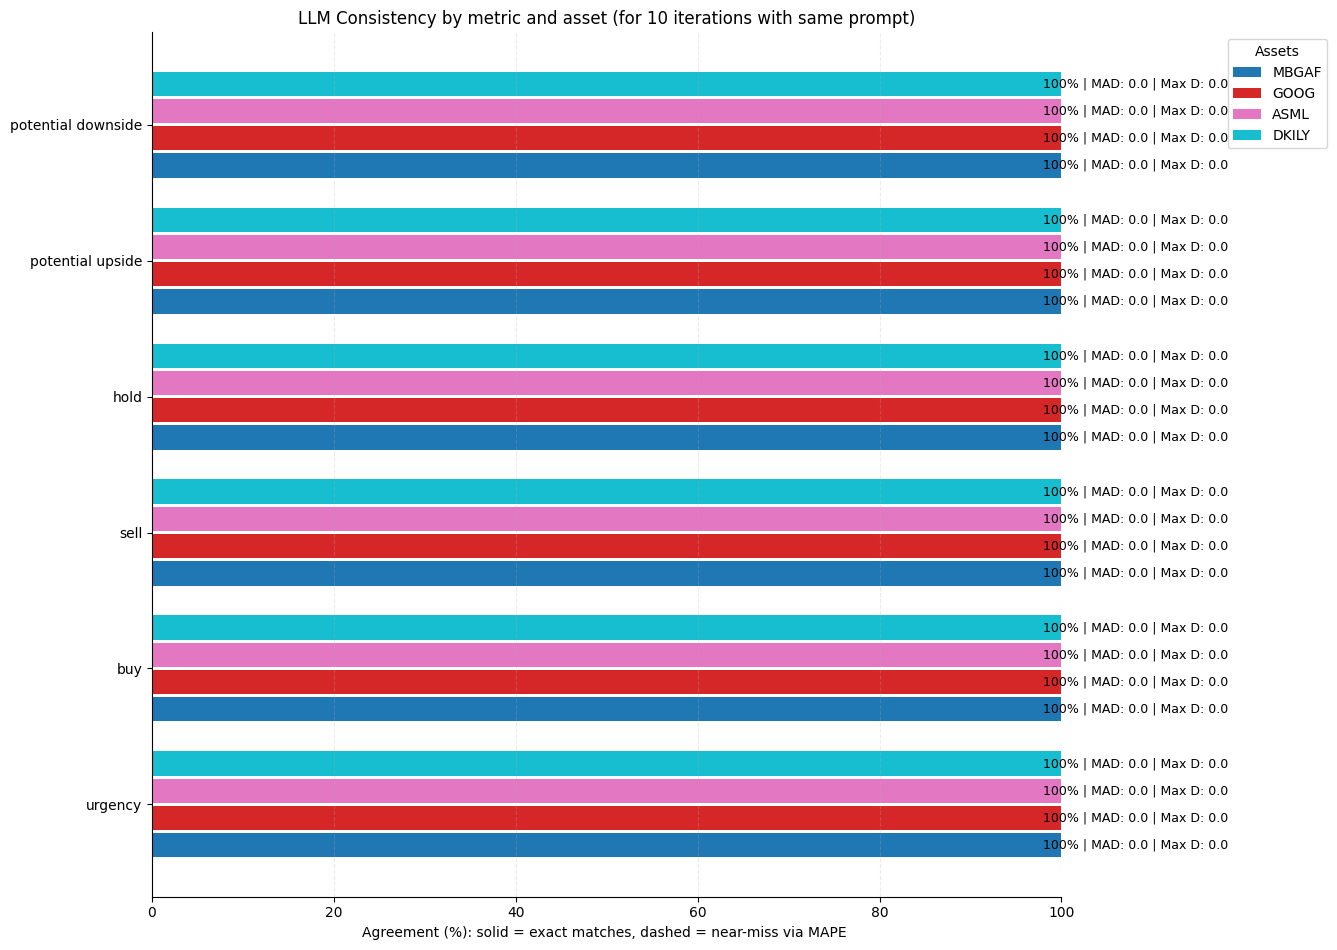

In [ ]:
def plot_consistency_grouped_horizontal_with_nearmiss_mape(
    stats_input: dict,
    metrics=None,
    annotate=True,
    round_decimals: int = 4,
    comment_title = None
):
    """
    Horizontal grouped bar chart (single Axes):
      • Solid bar  = exact consistency C (% identical values) per METRIC
      • Dashed ext = near-miss agreement via MAPE relativ zum Mehrheitswert (Mode)

    Near-miss (MAPE-basiert):
      - Bestimme gerundeten Mode M je (Asset, Metric).
      - Betrachte nur abweichende Werte D.
      - MAPE = mean(|v - M| / |M|) * 100  (falls |M|>0),
        sonst Fallback: SMAPE = mean(2|v-M| / (|v|+|M|)) * 100.
      - Gewicht w = 1 - min(1, MAPE/100)  (oder SMAPE/100 im Fallback).
      - Effective agreement A = C + (100 - C) * w.

    Unterstützte Eingaben:
      1) Neu (Assets oben):
         { "Asset A": {"buy": {...}, ...}, "Asset B": {...}, ... }
      2) Alt (Metriken oben): {"buy": {...}, "sell": {...}, ...} -> Asset "All".

    Erwartete Felder pro Metrik (sofern verfügbar):
      - count, identical_values_count
      - orig_values_list  (empfohlen, um MAPE zu berechnen)
      - mean, avg_abs_dev_pp, max_abs_dev_pp, avg_rel_dev_pct  (Fallbacks)

    Returns
    -------
    (fig, ax) : matplotlib Figure und Axes
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    if not isinstance(stats_input, dict) or not stats_input:
        raise ValueError("stats_input must be a non-empty dict.")

    METRICS_DEFAULT = [
        "urgency",
        "buy",
        "sell",
        "hold",
        "potential_upside",
        "potential_downside",
    ]
    metrics_order = metrics or METRICS_DEFAULT
    metrics_set = set(metrics_order)

    # --- Struktur erkennen (alt vs. neu) ---
    top_keys = set(stats_input.keys())
    looks_like_old = top_keys.issubset(metrics_set) and len(top_keys) > 0

    if looks_like_old:
        assets = ["All"]
        by_asset = {"All": stats_input}
    else:
        assets = list(stats_input.keys())
        by_asset = stats_input

    # --- Helper ---
    EPS = 1e-12

    def _mode_rounded(values, decimals=round_decimals):
        if not values:
            return np.nan
        arr = [round(float(v), decimals) for v in values]
        uniq, counts = np.unique(arr, return_counts=True)
        return float(uniq[int(np.argmax(counts))])

    def _mape_weight(values, M):
        """
        Liefert (w, used_metric) wobei w in [0,1].
        used_metric ist 'MAPE' oder 'SMAPE' (Fallback).
        """
        devs = [float(v) for v in values if round(float(v), round_decimals) != round(M, round_decimals)]
        if not devs:
            return np.nan, "NONE"  # keine Abweichungen -> kein near-miss nötig

        if abs(M) > EPS:
            mape = float(np.mean([abs(v - M) / abs(M) for v in devs])) * 100.0
            w = 1.0 - min(1.0, mape / 100.0)
            return w, "MAPE"
        else:
            # Fallback: SMAPE (robust bei M≈0)
            smape = float(np.mean([
                (2.0 * abs(v - M)) / (abs(v) + abs(M) + EPS) for v in devs
            ])) * 100.0
            w = 1.0 - min(1.0, smape / 100.0)
            return w, "SMAPE"

    # --- Tabelle bauen ---
    rows = []
    for asset in assets:
        mstats = by_asset.get(asset, {})
        for m in metrics_order:
            s = mstats.get(m, {}) if isinstance(mstats, dict) else {}
            count   = int(s.get("count", 0) or 0)
            idcount = int(s.get("identical_values_count", 0) or 0)
            with np.errstate(divide="ignore", invalid="ignore"):
                C = (idcount / count) * 100.0 if count else np.nan

            orig_vals = s.get("orig_values_list", None)
            if isinstance(orig_vals, (list, tuple)) and len(orig_vals) > 0:
                M = _mode_rounded(orig_vals, decimals=round_decimals)
                w, used = _mape_weight(orig_vals, M)
            else:
                # Fallbacks ohne Rohwerte:
                used = "FALLBACK"
                if s.get("avg_rel_dev_pct") is not None:
                    # approx. MAPE ~ avg_rel_dev_pct
                    mape = float(s["avg_rel_dev_pct"])
                    w = 1.0 - min(1.0, mape / 100.0)
                else:
                    # approx. MAPE ~ MAD/|mean|
                    mad = s.get("avg_abs_dev_pp")
                    mu  = s.get("mean")
                    if mad is not None and mu not in (None, 0):
                        approx_mape = abs(float(mad)) / (abs(float(mu)) + EPS) * 100.0
                        w = 1.0 - min(1.0, approx_mape / 100.0)
                    else:
                        w = np.nan

            if np.isfinite(C) and np.isfinite(w):
                A = C + (100.0 - C) * w
            else:
                A = C

            rows.append({
                "metric": m,
                "asset": asset,
                "consistency_pct": C,
                "effective_pct": A,
                "mad_pp": s.get("avg_abs_dev_pp", np.nan),
                "max_dev_pp": s.get("max_abs_dev_pp", np.nan),
            })

    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("No data to plot.")

    df["metric"] = pd.Categorical(df["metric"], categories=metrics_order, ordered=True)
    df.sort_values(["metric", "asset"], inplace=True)

    # --- Single-Axes, gruppierte horizontale Balken ---
    n_assets = len(assets)
    fig_width = max(14, 6 + 1.6 * n_assets)
    fig_height = max(8, 1.6 * len(metrics_order))
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    y_centers = np.arange(len(metrics_order))
    cluster_height = 0.8
    bar_height = cluster_height / max(n_assets, 1)

    cmap = plt.cm.get_cmap("tab10", max(n_assets, 3))
    asset_colors = {asset: cmap(i % cmap.N) for i, asset in enumerate(assets)}

    for j, asset in enumerate(assets):
        offset = (j - (n_assets - 1) / 2) * bar_height
        sub = df[df["asset"] == asset]
        y_pos = np.array([y_centers[metrics_order.index(m)] for m in sub["metric"]], dtype=float)

        cons = sub["consistency_pct"].to_numpy(dtype=float)
        eff  = sub["effective_pct"].to_numpy(dtype=float)
        mad  = sub["mad_pp"].to_numpy(dtype=float)
        mx   = sub["max_dev_pp"].to_numpy(dtype=float)

        # Solide Balken (C)
        bars = ax.barh(
            y_pos + offset,
            np.nan_to_num(cons, nan=0.0),
            height=bar_height * 0.9,
            label=asset,
            color=asset_colors[asset],
        )

        # Gestrichelte Erweiterung (A - C) in gleicher Farbe
        for y, cval, aval in zip(y_pos + offset, cons, eff):
            if np.isfinite(cval) and np.isfinite(aval) and aval > cval:
                ax.hlines(
                    y=y,
                    xmin=cval,
                    xmax=min(aval, 100.0),
                    colors=[asset_colors[asset]],
                    linestyles="--",
                    linewidth=2,
                )

        # Annotation inkl. MAD & Max
        if annotate:
            for rect, cval, aval, m_mad, m_max in zip(bars, cons, eff, mad, mx):
                if np.isfinite(cval):
                    txt = f"{cval:.0f}%"
                    if np.isfinite(aval) and aval > cval:
                        txt += f" → {aval:.0f}%"
                else:
                    txt = "n/a"

                if np.isfinite(m_mad) or np.isfinite(m_max):
                    mad_str = f"{m_mad:.1f}" if np.isfinite(m_mad) else "n/a"
                    max_str = f"{m_max:.1f}" if np.isfinite(m_max) else "n/a"
                    txt += f" | MAD: {mad_str} | Max D: {max_str} "

                x_end = aval if np.isfinite(aval) else (cval if np.isfinite(cval) else 0.0)
                ax.text(
                    min(x_end + 1.5, 98.0),
                    rect.get_y() + rect.get_height()/2,
                    txt,
                    va="center",
                    ha="left",
                    fontsize=9,
                )

    # Achsen & Legende
    ax.set_xlim(0, 100)
    ax.set_xlabel("Agreement (%): solid = exact matches, dashed = near-miss via MAPE ")
    ax.set_yticks(y_centers)
    ax.set_yticklabels([m.replace("_", " ") for m in metrics_order])
    ax.set_title("LLM Consistency by metric and asset" + (f" ({comment_title})" if comment_title else "") )
    ax.grid(True, axis="x", linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Legende oben rechts
    ax.legend(
        title="Assets",
        frameon=True,
        loc="upper right",
        bbox_to_anchor=(1.3, 1.0),
        ncols=1
    )

    fig.tight_layout()
    return fig, ax



fig, ax = plot_consistency_grouped_horizontal_with_nearmiss_mape(stats_summary, comment_title="for 10 iterations with same prompt")  # stats_input can be old or new structure